# Multi-Seed Ensemble Learning for Sideslip Angle Estimation

## Abstract

This notebook presents a comprehensive investigation of multi-seed ensemble learning for vehicle sideslip angle estimation under imbalanced regression conditions. We employ a systematic approach where identical neural network architectures are trained multiple times with different random initializations, and their predictions are aggregated to reduce variance and improve generalization performance.

## 1. Introduction

### 1.1 Motivation

Deep learning models are inherently sensitive to random initialization, introducing variability in final performance metrics. This stochasticity, while often viewed as a limitation, can be leveraged through ensemble methods to improve model robustness and predictive accuracy. In the context of imbalanced regression—where target distributions are heavily skewed—reducing prediction variance is particularly critical for rare (few-shot) samples.

### 1.2 Methodology Overview

Our approach implements a systematic ensemble framework:

1. **Independent Training**: Train K identical model architectures with different random seeds
2. **Prediction Aggregation**: Combine predictions through arithmetic mean or median
3. **Performance Evaluation**: Compare ensemble performance against individual models across multiple evaluation metrics

This methodology aims to exploit the bias-variance tradeoff by reducing prediction variance while maintaining low bias through consistent architecture and training procedures.

## 2. Experimental Setup

### 2.1 Dependencies and Environment Configuration

This section imports all required libraries and configures the computational environment. We use the SimpleGRU architecture with parameters derived from previous experimental optimization.

In [43]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm import tqdm
import warnings
import copy
from datetime import datetime
warnings.filterwarnings('ignore')

# Configure visualization
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 10

# Add project root to path
PROJECT_ROOT = Path.cwd().parent
sys.path.insert(0, str(PROJECT_ROOT))

# Import custom utilities and models
from utils.reproducibility_utils import seed_everything, seed_worker
from utils.data_loadingV2 import load_data, load_test_data
from utils.kaggle_metric import score as kaggle_score
from utils.band_mapping import load_band_mapping, calculate_band_mae

# Import model architecture
from models.vanilla_rnn import VanillaRNN

# Verify computational environment
print(f"PyTorch version: {torch.__version__}")
print(f"CUDA available: {torch.cuda.is_available()}")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Computation device: {device}")

PyTorch version: 2.9.1+cu128
CUDA available: True
Computation device: cuda


### 2.2 Hyperparameter Configuration

We define the experimental configuration including ensemble size, model architecture parameters, and training hyperparameters. All experiments use identical configurations except for the random seed to ensure fair comparison.

**Note**: This notebook uses the VanillaRNN architecture with parameters optimized from previous experiments (hidden_size=64, num_layers=1, no dropout).

In [44]:
# Path configuration
TRAIN_PATH = PROJECT_ROOT / "datasets_challenge" / "train"
TEST_PATH = PROJECT_ROOT / "datasets_challenge" / "test"
DIST_CSV = PROJECT_ROOT / "datasets_challenge" / "sideSlip_distribution.csv"
OUTPUT_DIR = PROJECT_ROOT / "Ensemble_Approach" / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

# Ensemble configuration
NUM_MODELS = 5  # Ensemble size (K)
BASE_SEED = 42
SEEDS = [BASE_SEED + i * 100 for i in range(NUM_MODELS)]  # Deterministic seed generation

# Model architecture configuration
MODEL_TYPE = "VanillaRNN"
MODEL_PARAMS = {
    "input_size": 22,      # Number of input features
    "hidden_size": 64,     # Hidden layer dimensionality (optimized from previous experiments)
    "num_layers": 1,       # Number of recurrent layers
    "dropout": 0.0         # Dropout probability for regularization
}

# Training hyperparameters
BATCH_SIZE = 256
SEQUENCE_LENGTH = 20       # Temporal window size
VAL_RATIO = 0.2            # Validation split ratio (V2 dataloader uses val_ratio, not train_ratio)
NUM_EPOCHS = 50            # Training epochs per model
LEARNING_RATE = 3e-4       # Initial learning rate
WEIGHT_DECAY = 1e-5        # L2 regularization coefficient

# Display configuration
print("\n" + "="*70)
print("EXPERIMENTAL CONFIGURATION")
print("="*70)
print(f"Ensemble size (K): {NUM_MODELS}")
print(f"Random seeds: {SEEDS}")
print(f"Model architecture: {MODEL_TYPE}")
print(f"Model parameters: {MODEL_PARAMS}")
print(f"Training epochs: {NUM_EPOCHS}")
print(f"Learning rate: {LEARNING_RATE}")
print("="*70 + "\n")


EXPERIMENTAL CONFIGURATION
Ensemble size (K): 5
Random seeds: [42, 142, 242, 342, 442]
Model architecture: VanillaRNN
Model parameters: {'input_size': 22, 'hidden_size': 64, 'num_layers': 1, 'dropout': 0.0}
Training epochs: 50
Learning rate: 0.0003



## 3. Data Preparation

### 3.1 Dataset Loading and Preprocessing

We load the training dataset and partition it into training and validation sets using a fixed ratio. The data preprocessing pipeline includes:

- Feature standardization (z-score normalization)
- Sequence windowing for temporal modeling
- Batch construction for mini-batch gradient descent

In [45]:
# Initialize random state for reproducibility
seed_everything(BASE_SEED)

# Load and partition data using V2 dataloader
train_loader, val_loader, scaler, train_dataset, val_dataset = load_data(
    train_path=str(TRAIN_PATH),
    val_ratio=VAL_RATIO,
    sequence_length=SEQUENCE_LENGTH,
    target='sideSlip',
    threshold=True,
    threshold_value=3.0,
    threshold_column='vxCG',
    batchsize=BATCH_SIZE,
    scaling=True,
    seed=BASE_SEED,
    shuffle=True
)

# Display dataset statistics
print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")
print(f"Approximate training samples: {len(train_loader) * BATCH_SIZE:,}")
print(f"Approximate validation samples: {len(val_loader) * BATCH_SIZE:,}")

# Verify data dimensions
for X, y in train_loader:
    input_size = X.shape[2]  # Get actual feature dimension from data
    print(f"\nInput tensor shape: {X.shape}")
    print(f"  - Batch size: {X.shape[0]}")
    print(f"  - Sequence length: {X.shape[1]}")
    print(f"  - Feature dimension: {X.shape[2]}")
    print(f"Target tensor shape: {y.shape}")
    break

# Update MODEL_PARAMS with actual input_size from data
MODEL_PARAMS["input_size"] = input_size
print(f"\n✅ Updated MODEL_PARAMS with input_size={input_size}")

V5 Data Loader: Stratified Temporal Split

Processing 22 files...
Total groups after threshold: 42

Train: Many=90.0%, Medium=7.8%, Few=2.2%
Val:   Many=95.8%, Medium=2.8%, Few=1.3%

Train: 111,841 sequences | Val: 25,239 sequences

Training batches: 437
Validation batches: 99
Approximate training samples: 111,872
Approximate validation samples: 25,344

Input tensor shape: torch.Size([256, 20, 22])
  - Batch size: 256
  - Sequence length: 20
  - Feature dimension: 22
Target tensor shape: torch.Size([256])

✅ Updated MODEL_PARAMS with input_size=22


## 4. Model Architecture

### 4.1 Model Instantiation

We use the VanillaRNN (Recurrent Neural Network) architecture for all ensemble members. The model uses a single RNN layer with ReLU activation and 64 hidden units, followed by a two-layer feedforward network for regression output. Each model instance shares identical architecture but is initialized with different random weights to create diversity in the ensemble.

In [46]:
def create_model(model_type, model_params):
    """
    Factory function for model instantiation.
    
    Args:
        model_type (str): Model architecture identifier
        model_params (dict): Model hyperparameters
    
    Returns:
        torch.nn.Module: Instantiated model
    """
    if model_type != "VanillaRNN":
        raise ValueError(f"Only VanillaRNN architecture is supported in this notebook.")
    
    return VanillaRNN(**model_params)

# Instantiate reference model for parameter counting
reference_model = create_model(MODEL_TYPE, MODEL_PARAMS)
total_params = sum(p.numel() for p in reference_model.parameters())
trainable_params = sum(p.numel() for p in reference_model.parameters() if p.requires_grad)

print(f"Model architecture: {MODEL_TYPE}")
print(f"Total parameters: {total_params:,}")
print(f"Trainable parameters: {trainable_params:,}")
print(f"\nModel structure:\n{reference_model}")

Model architecture: VanillaRNN
Total parameters: 9,857
Trainable parameters: 9,857

Model structure:
VanillaRNN(
  (rnn): RNN(22, 64, batch_first=True)
  (dropout): Identity()
  (fc): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=1, bias=True)
  )
)


## 5. Training Procedure

### 5.1 Single-Model Training Function

We implement a standard supervised learning procedure using Mean Absolute Error (MAE) as the loss function. The training loop includes:

- **Optimization**: AdamW optimizer with cosine annealing learning rate schedule
- **Regularization**: Dropout, weight decay, and gradient clipping
- **Validation**: Performance monitoring on held-out validation set
- **Early stopping**: Optional termination based on validation performance plateau

Each model is trained independently with a unique random seed to ensure diverse initializations.

In [47]:
def train_model_with_seed(model_type, model_params, train_loader, val_loader, 
                          seed, device, band_dict, epochs=NUM_EPOCHS,
                          lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY,
                          verbose=True):
    """
    Train a single model with specified random seed.
    
    Args:
        model_type (str): Model architecture identifier
        model_params (dict): Model hyperparameters
        train_loader (DataLoader): Training data loader
        val_loader (DataLoader): Validation data loader
        seed (int): Random seed for reproducibility
        device (torch.device): Computation device
        band_dict (dict): Band mapping for stratified evaluation
        epochs (int): Number of training epochs
        lr (float): Initial learning rate
        weight_decay (float): L2 regularization coefficient
        verbose (bool): Print training progress
    
    Returns:
        model (torch.nn.Module): Trained model
        metrics (dict): Final validation metrics
        history (dict): Training history
    """
    # Set random seed for reproducibility
    seed_everything(seed)
    
    # Initialize model
    model = create_model(model_type, model_params).to(device)
    
    # Define loss function and optimizer
    criterion = nn.L1Loss()  # Mean Absolute Error
    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=weight_decay
    )
    
    # Learning rate scheduler with cosine annealing
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
        optimizer,
        T_max=epochs,
        eta_min=lr * 0.01
    )
    
    # Training history
    history = {
        'train_loss': [],
        'val_loss': [],
        'learning_rate': []
    }
    
    if verbose:
        print(f"\n{'='*70}")
        print(f"Training {model_type} with seed {seed}")
        print(f"{'='*70}")
    
    best_val_loss = float('inf')
    best_model_state = None
    
    # Training loop
    for epoch in range(epochs):
        # Training phase
        model.train()
        train_losses = []
        
        for X, y in train_loader:
            X, y = X.to(device), y.to(device)
            if y.dim() == 1:
                y = y.unsqueeze(1)
            
            # Forward pass
            optimizer.zero_grad()
            predictions = model(X)
            loss = criterion(predictions, y)
            
            # Backward pass with gradient clipping
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            
            train_losses.append(loss.item())
        
        # Validation phase
        model.eval()
        val_losses = []
        
        with torch.no_grad():
            for X, y in val_loader:
                X, y = X.to(device), y.to(device)
                if y.dim() == 1:
                    y = y.unsqueeze(1)
                
                predictions = model(X)
                loss = criterion(predictions, y)
                val_losses.append(loss.item())
        
        # Update learning rate
        scheduler.step()
        
        # Record history
        epoch_train_loss = np.mean(train_losses)
        epoch_val_loss = np.mean(val_losses)
        current_lr = optimizer.param_groups[0]['lr']
        
        history['train_loss'].append(epoch_train_loss)
        history['val_loss'].append(epoch_val_loss)
        history['learning_rate'].append(current_lr)
        
        # Save best model
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            best_model_state = copy.deepcopy(model.state_dict())
        
        # Print progress
        if verbose and (epoch + 1) % 10 == 0:
            print(
                f"Epoch {epoch+1:03d}/{epochs}: "
                f"train_loss={epoch_train_loss:.4f}, "
                f"val_loss={epoch_val_loss:.4f}, "
                f"lr={current_lr:.2e}"
            )
    
    # Restore best model
    model.load_state_dict(best_model_state)
    
    # Calculate final metrics with band-specific evaluation
    metrics = evaluate_model(model, val_loader, device, band_dict)
    
    if verbose:
        print(f"\nFinal validation metrics:")
        print(f"  Overall MAE: {metrics.get('val_mae', 'N/A')}")
        print(f"  Few-shot MAE: {metrics.get('few_mae', 'N/A')}")
        print(f"  Medium-shot MAE: {metrics.get('medium_mae', 'N/A')}")
        print(f"  Many-shot MAE: {metrics.get('many_mae', 'N/A')}")
    
    return model, metrics, history


def evaluate_model(model, data_loader, device, band_dict):
    """
    Evaluate model performance with band-specific metrics.
    
    Args:
        model (torch.nn.Module): Model to evaluate
        data_loader (DataLoader): Validation data loader
        device (torch.device): Computation device
        band_dict (dict): Band mapping for stratified evaluation
    
    Returns:
        dict: Evaluation metrics
    """
    model.eval()
    all_preds = []
    all_targets = []
    
    with torch.no_grad():
        for X, y in data_loader:
            X = X.to(device)
            predictions = model(X).cpu().numpy().flatten()
            targets = y.numpy().flatten() if y.dim() > 1 else y.numpy()
            
            all_preds.extend(predictions)
            all_targets.extend(targets)
    
    all_preds = np.array(all_preds)
    all_targets = np.array(all_targets)
    
    # Overall MAE
    val_mae = np.mean(np.abs(all_preds - all_targets))
    
    # Initialize metrics with overall MAE
    metrics = {'val_mae': val_mae}
    
    # Band-specific MAE using calculate_band_mae utility
    try:
        band_metrics = calculate_band_mae(all_preds, all_targets, band_dict)
        # The function returns keys like 'many_mae', 'medium_mae', 'few_mae'
        # We keep them as-is
        metrics.update(band_metrics)
    except Exception as e:
        print(f"Warning: Could not calculate band-specific metrics: {e}")
    
    return metrics

### 5.2 Baseline Model Training

Before training the ensemble, we establish a baseline by training a single model with the base seed (42). This baseline represents standard single-model performance and serves as the primary comparison point for evaluating ensemble benefits.

In [48]:
# Load band mapping for evaluation
band_dict = load_band_mapping(str(DIST_CSV))

print("\n" + "="*70)
print("BASELINE MODEL TRAINING")
print("="*70)
print(f"Training single model with seed {BASE_SEED} as baseline comparison")

# Train baseline model
baseline_model, baseline_metrics, baseline_history = train_model_with_seed(
    model_type=MODEL_TYPE,
    model_params=MODEL_PARAMS,
    train_loader=train_loader,
    val_loader=val_loader,
    seed=BASE_SEED,
    device=device,
    band_dict=band_dict,
    verbose=True
)

# Generate baseline predictions on validation set
baseline_model.eval()
baseline_preds = []
baseline_targets = []

with torch.no_grad():
    for X, y in val_loader:
        X = X.to(device)
        predictions = baseline_model(X).cpu().numpy().flatten()
        targets = y.numpy().flatten() if y.dim() > 1 else y.numpy()
        baseline_preds.extend(predictions)
        baseline_targets.extend(targets)

baseline_preds = np.array(baseline_preds)
baseline_targets = np.array(baseline_targets)

# Display baseline results
print("\n" + "="*70)
print("BASELINE MODEL RESULTS")
print("="*70)
print(f"Validation MAE:        {baseline_metrics['val_mae']:.4f}")
print(f"Few-shot MAE:          {baseline_metrics.get('few_mae', 'N/A'):.4f}")
print(f"Medium-shot MAE:       {baseline_metrics.get('medium_mae', 'N/A'):.4f}")
print(f"Many-shot MAE:         {baseline_metrics.get('many_mae', 'N/A'):.4f}")
print("="*70 + "\n")


BASELINE MODEL TRAINING
Training single model with seed 42 as baseline comparison

Training VanillaRNN with seed 42
Epoch 010/50: train_loss=0.1679, val_loss=0.1807, lr=2.72e-04
Epoch 020/50: train_loss=0.1533, val_loss=0.1680, lr=1.97e-04
Epoch 030/50: train_loss=0.1464, val_loss=0.1630, lr=1.06e-04
Epoch 040/50: train_loss=0.1413, val_loss=0.1618, lr=3.14e-05
Epoch 050/50: train_loss=0.1396, val_loss=0.1669, lr=3.00e-06

Final validation metrics:
  Overall MAE: 0.1578025072813034
  Few-shot MAE: 0.3978143036365509
  Medium-shot MAE: 0.2501673996448517
  Many-shot MAE: 0.138320654630661

BASELINE MODEL RESULTS
Validation MAE:        0.1578
Few-shot MAE:          0.3978
Medium-shot MAE:       0.2502
Many-shot MAE:         0.1383



### 5.3 Ensemble Training

We train K independent models sequentially, each with a unique random seed. All other hyperparameters remain fixed across ensemble members to isolate the effect of random initialization on model performance.

In [49]:
# Storage for ensemble components
ensemble_models = []
ensemble_metrics = []
ensemble_histories = []

# Sequential training of ensemble members
print("\n" + "="*70)
print(f"ENSEMBLE TRAINING: {NUM_MODELS} MODELS")
print("="*70)

for i, seed in enumerate(SEEDS):
    print(f"\n[{i+1}/{NUM_MODELS}] Training model with seed {seed}")
    
    model, metrics, history = train_model_with_seed(
        model_type=MODEL_TYPE,
        model_params=MODEL_PARAMS,
        train_loader=train_loader,
        val_loader=val_loader,
        seed=seed,
        device=device,
        band_dict=band_dict,
        verbose=True
    )
    
    ensemble_models.append(model)
    ensemble_metrics.append(metrics)
    ensemble_histories.append(history)

print("\n" + "="*70)
print("ENSEMBLE TRAINING COMPLETE")
print("="*70)


ENSEMBLE TRAINING: 5 MODELS

[1/5] Training model with seed 42

Training VanillaRNN with seed 42
Epoch 010/50: train_loss=0.1679, val_loss=0.1807, lr=2.72e-04
Epoch 020/50: train_loss=0.1533, val_loss=0.1680, lr=1.97e-04
Epoch 030/50: train_loss=0.1464, val_loss=0.1630, lr=1.06e-04
Epoch 040/50: train_loss=0.1413, val_loss=0.1618, lr=3.14e-05
Epoch 050/50: train_loss=0.1396, val_loss=0.1669, lr=3.00e-06

Final validation metrics:
  Overall MAE: 0.1578025072813034
  Few-shot MAE: 0.3978143036365509
  Medium-shot MAE: 0.2501673996448517
  Many-shot MAE: 0.138320654630661

[2/5] Training model with seed 142

Training VanillaRNN with seed 142
Epoch 010/50: train_loss=0.1676, val_loss=0.1868, lr=2.72e-04
Epoch 020/50: train_loss=0.1524, val_loss=0.1629, lr=1.97e-04
Epoch 030/50: train_loss=0.1443, val_loss=0.1594, lr=1.06e-04
Epoch 040/50: train_loss=0.1397, val_loss=0.1671, lr=3.14e-05
Epoch 050/50: train_loss=0.1379, val_loss=0.1627, lr=3.00e-06

Final validation metrics:
  Overall MAE: 

## 6. Results and Analysis

### 6.1 Individual Model Performance

We first analyze the performance of individual ensemble members to quantify the variance introduced by random initialization.

In [50]:
# Construct performance summary table
summary_data = []
for i, (seed, metrics) in enumerate(zip(SEEDS, ensemble_metrics)):
    summary_data.append({
        'Model': f'Model_{i+1}',
        'Seed': seed,
        'Val_MAE': metrics.get('val_mae', np.nan),
        'Few_Shot_MAE': metrics.get('few_mae', np.nan),
        'Medium_Shot_MAE': metrics.get('medium_mae', np.nan),
        'Many_Shot_MAE': metrics.get('many_mae', np.nan)
    })

summary_df = pd.DataFrame(summary_data)

print("\n" + "="*70)
print("INDIVIDUAL MODEL PERFORMANCE")
print("="*70)
print(summary_df.to_string(index=False))
print("\n" + "-"*70)
print(f"Mean validation MAE: {summary_df['Val_MAE'].mean():.4f} ± {summary_df['Val_MAE'].std():.4f}")
print(f"Min validation MAE:  {summary_df['Val_MAE'].min():.4f}")
print(f"Max validation MAE:  {summary_df['Val_MAE'].max():.4f}")
print(f"Coefficient of variation: {(summary_df['Val_MAE'].std() / summary_df['Val_MAE'].mean() * 100):.2f}%")
print("="*70 + "\n")


INDIVIDUAL MODEL PERFORMANCE
  Model  Seed  Val_MAE  Few_Shot_MAE  Medium_Shot_MAE  Many_Shot_MAE
Model_1    42 0.157803      0.397814         0.250167       0.138321
Model_2   142 0.158569      0.447721         0.282317       0.138846
Model_3   242 0.154083      0.474533         0.246113       0.135259
Model_4   342 0.157037      0.395313         0.235155       0.134217
Model_5   442 0.156993      0.424383         0.266300       0.131595

----------------------------------------------------------------------
Mean validation MAE: 0.1569 ± 0.0017
Min validation MAE:  0.1541
Max validation MAE:  0.1586
Coefficient of variation: 1.08%



### 6.2 Ensemble Prediction

We implement prediction aggregation through arithmetic averaging. Alternative aggregation strategies (median, weighted averaging) can be substituted as needed.

In [51]:
def ensemble_predict(models, data_loader, device, averaging='mean'):
    """
    Generate ensemble predictions via model averaging.
    
    Args:
        models (list): List of trained models
        data_loader (DataLoader): Data loader for inference
        device (torch.device): Computation device
        averaging (str): Aggregation method ('mean' or 'median')
    
    Returns:
        ensemble_preds (np.ndarray): Aggregated predictions
        individual_preds (list): Individual model predictions
        targets (np.ndarray): Ground truth labels
    """
    all_preds = [[] for _ in range(len(models))]
    all_targets = []
    
    # Set all models to evaluation mode
    for model in models:
        model.eval()
    
    # Generate predictions from each model
    with torch.no_grad():
        for X, y in tqdm(data_loader, desc="Generating ensemble predictions"):
            X = X.to(device)
            
            # Collect predictions from each ensemble member
            for i, model in enumerate(models):
                pred = model(X).cpu().numpy().flatten()
                all_preds[i].extend(pred)
            
            targets = y.numpy().flatten() if y.dim() > 1 else y.numpy()
            all_targets.extend(targets)
    
    # Convert to numpy arrays
    individual_preds = [np.array(preds) for preds in all_preds]
    targets = np.array(all_targets)
    
    # Stack predictions for aggregation
    stacked_preds = np.stack(individual_preds, axis=0)  # Shape: (K, N)
    
    # Aggregate predictions
    if averaging == 'mean':
        ensemble_preds = np.mean(stacked_preds, axis=0)
    elif averaging == 'median':
        ensemble_preds = np.median(stacked_preds, axis=0)
    else:
        raise ValueError(f"Unknown averaging method: {averaging}")
    
    return ensemble_preds, individual_preds, targets

### 6.3 Ensemble Performance Evaluation

We compare the ensemble's aggregated predictions against individual model performance to quantify the benefit of model averaging.

In [52]:
# Generate ensemble predictions on validation set
ensemble_preds, individual_preds, val_targets = ensemble_predict(
    models=ensemble_models,
    data_loader=val_loader,
    device=device,
    averaging='mean'
)

# Calculate ensemble performance
ensemble_mae = np.mean(np.abs(ensemble_preds - val_targets))
mean_individual_mae = summary_df['Val_MAE'].mean()
best_individual_mae = summary_df['Val_MAE'].min()
baseline_mae = baseline_metrics['val_mae']

# Calculate relative improvements
improvement_over_baseline = ((baseline_mae - ensemble_mae) / baseline_mae) * 100
improvement_over_mean = ((mean_individual_mae - ensemble_mae) / mean_individual_mae) * 100
improvement_over_best = ((best_individual_mae - ensemble_mae) / best_individual_mae) * 100

# Display results
print("\n" + "="*70)
print("ENSEMBLE PERFORMANCE ANALYSIS")
print("="*70)
print(f"Aggregation method: Mean averaging")
print(f"\nPerformance metrics:")
print(f"  Baseline model MAE:       {baseline_mae:.4f} (single seed {BASE_SEED})")
print(f"  Ensemble MAE:             {ensemble_mae:.4f}")
print(f"  Mean ensemble member MAE: {mean_individual_mae:.4f}")
print(f"  Best ensemble member MAE: {best_individual_mae:.4f}")
print(f"\nRelative improvements:")
print(f"  vs. Baseline:             {improvement_over_baseline:+.2f}% 🎯")
print(f"  vs. Mean ensemble member: {improvement_over_mean:+.2f}%")
print(f"  vs. Best ensemble member: {improvement_over_best:+.2f}%")
print(f"\nVariance reduction:")
pred_std = np.std(np.stack(individual_preds), axis=0)
print(f"  Mean prediction std:      {pred_std.mean():.4f}")
print(f"  Median prediction std:    {np.median(pred_std):.4f}")
print(f"  Max prediction std:       {pred_std.max():.4f}")
print("="*70 + "\n")

Generating ensemble predictions: 100%|██████████| 99/99 [00:00<00:00, 193.73it/s]


ENSEMBLE PERFORMANCE ANALYSIS
Aggregation method: Mean averaging

Performance metrics:
  Baseline model MAE:       0.1578 (single seed 42)
  Ensemble MAE:             0.1487
  Mean ensemble member MAE: 0.1569
  Best ensemble member MAE: 0.1541

Relative improvements:
  vs. Baseline:             +5.76% 🎯
  vs. Mean ensemble member: +5.22%
  vs. Best ensemble member: +3.49%

Variance reduction:
  Mean prediction std:      0.0556
  Median prediction std:    0.0458
  Max prediction std:       0.3527



## 7. Visualization

### 7.1 Performance Comparison

Visual comparison of individual model performance against ensemble aggregation.

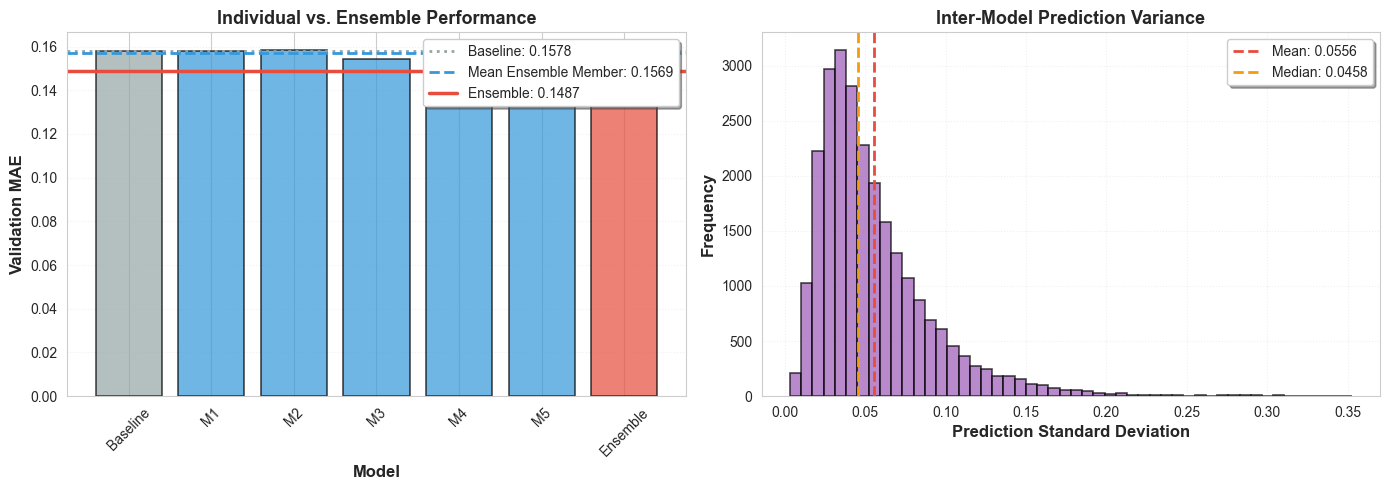

In [53]:
# Create figure for performance comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: MAE comparison
models_list = ['Baseline'] + [f'M{i+1}' for i in range(NUM_MODELS)] + ['Ensemble']
mae_values = [baseline_mae] + summary_df['Val_MAE'].tolist() + [ensemble_mae]
colors = ['#95a5a6'] + ['#3498db'] * NUM_MODELS + ['#e74c3c']

bars = axes[0].bar(models_list, mae_values, color=colors, alpha=0.7, edgecolor='black', linewidth=1.2)
axes[0].axhline(y=baseline_mae, color='#95a5a6', linestyle=':', linewidth=2,
                label=f'Baseline: {baseline_mae:.4f}')
axes[0].axhline(y=mean_individual_mae, color='#3498db', linestyle='--', linewidth=2,
                label=f'Mean Ensemble Member: {mean_individual_mae:.4f}')
axes[0].axhline(y=ensemble_mae, color='#e74c3c', linestyle='-', linewidth=2.5,
                label=f'Ensemble: {ensemble_mae:.4f}')
axes[0].set_ylabel('Validation MAE', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Model', fontsize=12, fontweight='bold')
axes[0].set_title('Individual vs. Ensemble Performance', fontsize=13, fontweight='bold')
axes[0].legend(loc='upper right', frameon=True, shadow=True)
axes[0].grid(axis='y', alpha=0.3, linestyle=':')
axes[0].tick_params(axis='x', rotation=45)

# Plot 2: Prediction variance distribution
pred_std = np.std(np.stack(individual_preds), axis=0)
axes[1].hist(pred_std, bins=50, alpha=0.7, color='#9b59b6', edgecolor='black', linewidth=1.2)
axes[1].axvline(x=pred_std.mean(), color='#e74c3c', linestyle='--', linewidth=2,
                label=f'Mean: {pred_std.mean():.4f}')
axes[1].axvline(x=np.median(pred_std), color='#f39c12', linestyle='--', linewidth=2,
                label=f'Median: {np.median(pred_std):.4f}')
axes[1].set_xlabel('Prediction Standard Deviation', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Frequency', fontsize=12, fontweight='bold')
axes[1].set_title('Inter-Model Prediction Variance', fontsize=13, fontweight='bold')
axes[1].legend(loc='upper right', frameon=True, shadow=True)
axes[1].grid(alpha=0.3, linestyle=':')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'ensemble_performance.png', dpi=300, bbox_inches='tight')
plt.show()

### 7.2 Baseline vs Ensemble Comparison

Direct visual comparison between the baseline single-seed model and the ensemble to demonstrate the improvement from model averaging.

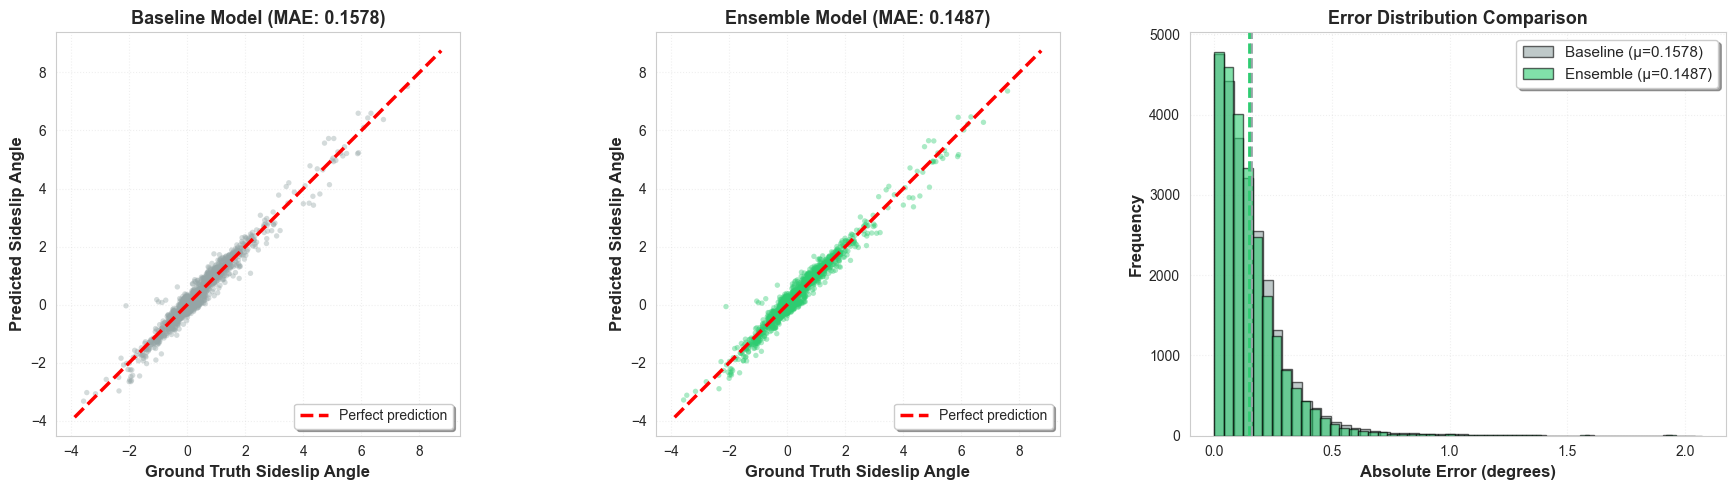


STATISTICAL COMPARISON: BASELINE vs ENSEMBLE
Baseline MAE:          0.1578 ± 0.1514
Ensemble MAE:          0.1487 ± 0.1416
Absolute improvement:  0.0091
Relative improvement:  5.76%

Paired t-test:
  t-statistic:         24.5052
  p-value:             0.000000
  Significance:        *** (p < 0.001) - Highly significant!



In [54]:
# Create comparison plots: Baseline vs Ensemble
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Sample for visualization efficiency
sample_size = min(2000, len(val_targets))
indices = np.random.choice(len(val_targets), sample_size, replace=False)

# Plot 1: Baseline model
axes[0].scatter(baseline_targets[indices], baseline_preds[indices], 
                alpha=0.4, s=15, c='#95a5a6', edgecolors='none')
axes[0].plot([val_targets.min(), val_targets.max()], 
             [val_targets.min(), val_targets.max()], 
             'r--', lw=2.5, label='Perfect prediction')
axes[0].set_xlabel('Ground Truth Sideslip Angle', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Predicted Sideslip Angle', fontsize=12, fontweight='bold')
axes[0].set_title(f'Baseline Model (MAE: {baseline_mae:.4f})', fontsize=13, fontweight='bold')
axes[0].legend(loc='lower right', frameon=True, shadow=True)
axes[0].grid(alpha=0.3, linestyle=':')
axes[0].set_aspect('equal', adjustable='box')

# Plot 2: Ensemble predictions
axes[1].scatter(val_targets[indices], ensemble_preds[indices], 
                alpha=0.4, s=15, c='#2ecc71', edgecolors='none')
axes[1].plot([val_targets.min(), val_targets.max()], 
             [val_targets.min(), val_targets.max()], 
             'r--', lw=2.5, label='Perfect prediction')
axes[1].set_xlabel('Ground Truth Sideslip Angle', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Predicted Sideslip Angle', fontsize=12, fontweight='bold')
axes[1].set_title(f'Ensemble Model (MAE: {ensemble_mae:.4f})', fontsize=13, fontweight='bold')
axes[1].legend(loc='lower right', frameon=True, shadow=True)
axes[1].grid(alpha=0.3, linestyle=':')
axes[1].set_aspect('equal', adjustable='box')

# Plot 3: Error comparison
baseline_errors = np.abs(baseline_preds - baseline_targets)
ensemble_errors = np.abs(ensemble_preds - val_targets)

axes[2].hist(baseline_errors, bins=50, alpha=0.6, label=f'Baseline (μ={baseline_errors.mean():.4f})', 
             color='#95a5a6', edgecolor='black', linewidth=1)
axes[2].hist(ensemble_errors, bins=50, alpha=0.6, label=f'Ensemble (μ={ensemble_errors.mean():.4f})', 
             color='#2ecc71', edgecolor='black', linewidth=1)
axes[2].axvline(x=baseline_errors.mean(), color='#95a5a6', linestyle='--', linewidth=2)
axes[2].axvline(x=ensemble_errors.mean(), color='#2ecc71', linestyle='--', linewidth=2)
axes[2].set_xlabel('Absolute Error (degrees)', fontsize=12, fontweight='bold')
axes[2].set_ylabel('Frequency', fontsize=12, fontweight='bold')
axes[2].set_title('Error Distribution Comparison', fontsize=13, fontweight='bold')
axes[2].legend(loc='upper right', frameon=True, shadow=True, fontsize=11)
axes[2].grid(alpha=0.3, linestyle=':')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'baseline_vs_ensemble.png', dpi=300, bbox_inches='tight')
plt.show()

# Calculate and display statistical significance
from scipy import stats
improvement_percentage = ((baseline_errors.mean() - ensemble_errors.mean()) / baseline_errors.mean()) * 100
t_stat, p_value = stats.ttest_rel(baseline_errors, ensemble_errors)

print("\n" + "="*70)
print("STATISTICAL COMPARISON: BASELINE vs ENSEMBLE")
print("="*70)
print(f"Baseline MAE:          {baseline_errors.mean():.4f} ± {baseline_errors.std():.4f}")
print(f"Ensemble MAE:          {ensemble_errors.mean():.4f} ± {ensemble_errors.std():.4f}")
print(f"Absolute improvement:  {baseline_errors.mean() - ensemble_errors.mean():.4f}")
print(f"Relative improvement:  {improvement_percentage:.2f}%")
print(f"\nPaired t-test:")
print(f"  t-statistic:         {t_stat:.4f}")
print(f"  p-value:             {p_value:.6f}")
if p_value < 0.001:
    print(f"  Significance:        *** (p < 0.001) - Highly significant!")
elif p_value < 0.01:
    print(f"  Significance:        ** (p < 0.01) - Very significant")
elif p_value < 0.05:
    print(f"  Significance:        * (p < 0.05) - Significant")
else:
    print(f"  Significance:        n.s. (p >= 0.05) - Not significant")
print("="*70 + "\n")

### 7.3 Prediction Quality Analysis

Scatter plots comparing predicted vs. actual sideslip angles for the best individual model and the ensemble.

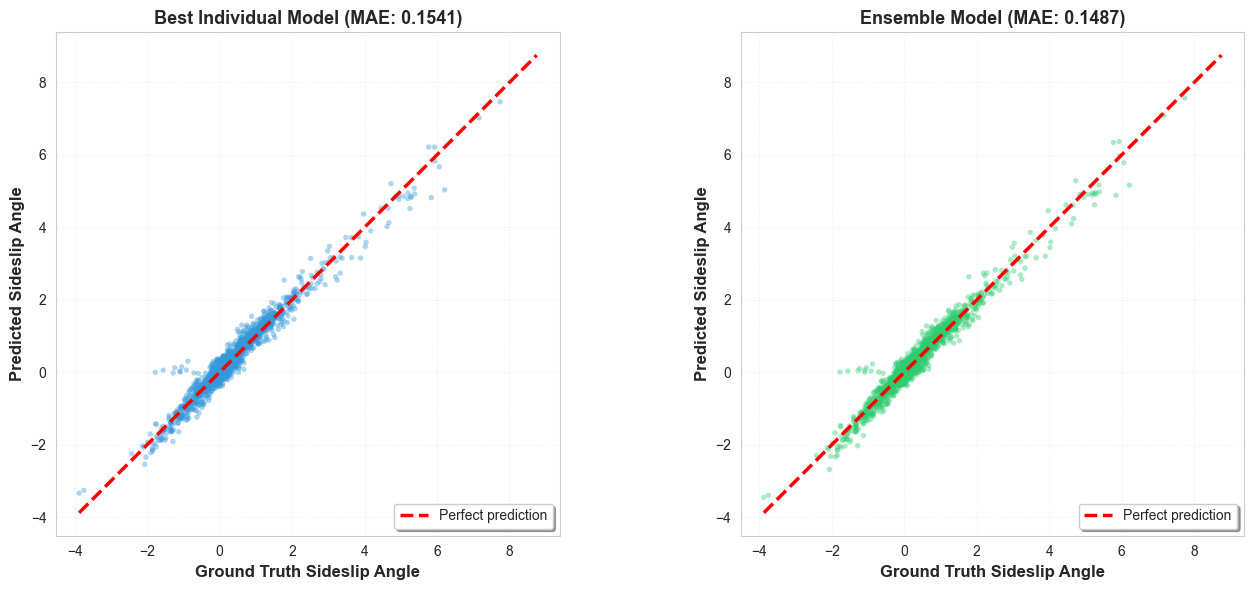

In [55]:
# Create scatter plots for prediction quality
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Sample for visualization efficiency
sample_size = min(2000, len(val_targets))
indices = np.random.choice(len(val_targets), sample_size, replace=False)

# Plot 1: Best individual model
best_model_idx = summary_df['Val_MAE'].idxmin()
best_mae = summary_df.loc[best_model_idx, 'Val_MAE']

axes[0].scatter(val_targets[indices], individual_preds[best_model_idx][indices], 
                alpha=0.4, s=15, c='#3498db', edgecolors='none')
axes[0].plot([val_targets.min(), val_targets.max()], 
             [val_targets.min(), val_targets.max()], 
             'r--', lw=2.5, label='Perfect prediction')
axes[0].set_xlabel('Ground Truth Sideslip Angle', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Predicted Sideslip Angle', fontsize=12, fontweight='bold')
axes[0].set_title(f'Best Individual Model (MAE: {best_mae:.4f})', fontsize=13, fontweight='bold')
axes[0].legend(loc='lower right', frameon=True, shadow=True)
axes[0].grid(alpha=0.3, linestyle=':')
axes[0].set_aspect('equal', adjustable='box')

# Plot 2: Ensemble predictions
axes[1].scatter(val_targets[indices], ensemble_preds[indices], 
                alpha=0.4, s=15, c='#2ecc71', edgecolors='none')
axes[1].plot([val_targets.min(), val_targets.max()], 
             [val_targets.min(), val_targets.max()], 
             'r--', lw=2.5, label='Perfect prediction')
axes[1].set_xlabel('Ground Truth Sideslip Angle', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Predicted Sideslip Angle', fontsize=12, fontweight='bold')
axes[1].set_title(f'Ensemble Model (MAE: {ensemble_mae:.4f})', fontsize=13, fontweight='bold')
axes[1].legend(loc='lower right', frameon=True, shadow=True)
axes[1].grid(alpha=0.3, linestyle=':')
axes[1].set_aspect('equal', adjustable='box')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'predictions_vs_ground_truth.png', dpi=300, bbox_inches='tight')
plt.show()

### 7.4 Training Dynamics

Visualization of training and validation loss curves across all ensemble members to assess convergence behavior and overfitting.

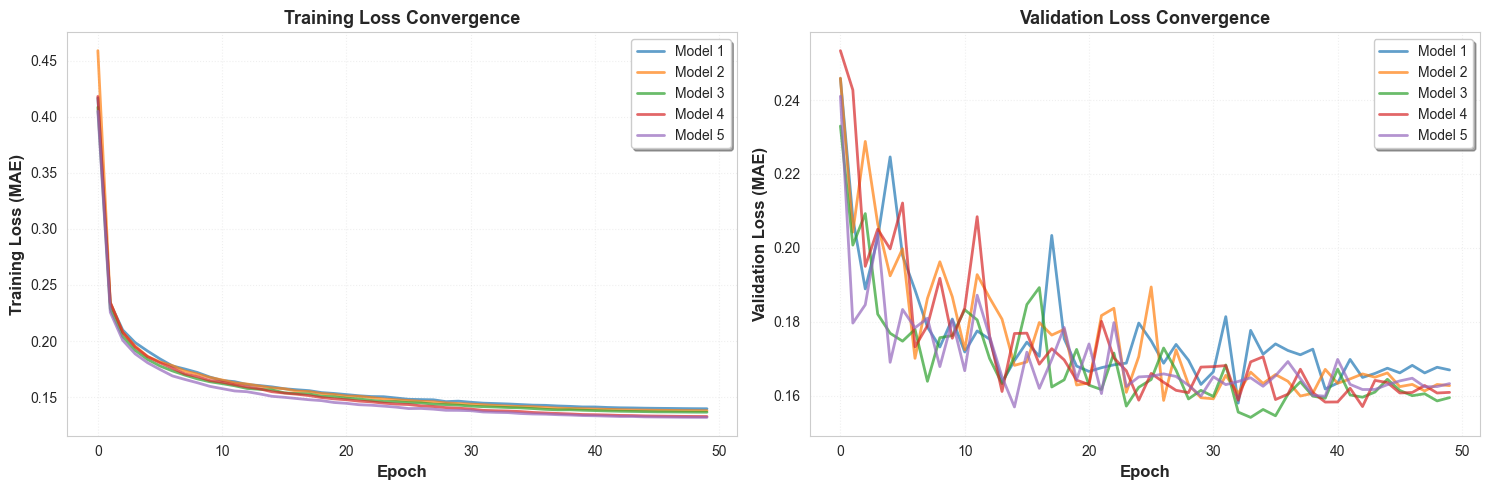

In [56]:
# Plot training histories
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Plot 1: Training loss
for i, history in enumerate(ensemble_histories):
    axes[0].plot(history['train_loss'], label=f'Model {i+1}', alpha=0.7, linewidth=2)
axes[0].set_xlabel('Epoch', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Training Loss (MAE)', fontsize=12, fontweight='bold')
axes[0].set_title('Training Loss Convergence', fontsize=13, fontweight='bold')
axes[0].legend(loc='upper right', frameon=True, shadow=True)
axes[0].grid(alpha=0.3, linestyle=':')

# Plot 2: Validation loss
for i, history in enumerate(ensemble_histories):
    axes[1].plot(history['val_loss'], label=f'Model {i+1}', alpha=0.7, linewidth=2)
axes[1].set_xlabel('Epoch', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Validation Loss (MAE)', fontsize=12, fontweight='bold')
axes[1].set_title('Validation Loss Convergence', fontsize=13, fontweight='bold')
axes[1].legend(loc='upper right', frameon=True, shadow=True)
axes[1].grid(alpha=0.3, linestyle=':')

plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'training_histories.png', dpi=300, bbox_inches='tight')
plt.show()

## 8. Test Set Inference

### 8.1 Load Test Data

Load the test dataset using the same preprocessing pipeline as training.

In [61]:
# Load test dataset using V2 dataloader
columns_to_drop = ['sideSlip', 'vyCG', 'latitude', 'longitude', 'time']
test_loader = load_test_data(
    test_path=str(TEST_PATH),
    scaler=scaler,
    columns_to_drop=columns_to_drop,
    sequence_length=SEQUENCE_LENGTH,
    threshold_value=3.0,
    threshold_column='vxCG',
    batchsize=BATCH_SIZE,
    seed=BASE_SEED
)

print(f"Test set batches: {len(test_loader)}")
print(f"Approximate test samples: {len(test_loader) * BATCH_SIZE:,}")

📂 Loading Test Data (V1-Compatible)

Found 11 test files
🔧 Applying threshold per file: vxCG > 3.0 (grouping)

   test_part_001.csv         | 4 groups, 1,428 samples
   test_part_002.csv         | 1 groups, 10,190 samples
   test_part_003.csv         | No valid groups
   test_part_004.csv         | 2 groups, 6,914 samples
   test_part_005.csv         | 1 groups, 11,260 samples
   test_part_006.csv         | 1 groups, 10,256 samples
   test_part_007.csv         | 2 groups, 389 samples
   test_part_008.csv         | 2 groups, 3,177 samples
   test_part_009.csv         | 1 groups, 1,595 samples
   test_part_010.csv         | 1 groups, 3,168 samples
   test_part_011.csv         | 1 groups, 1,271 samples

✅ Total groups: 16

📊 Test Data Summary:
   Raw samples: 68,806
   After threshold: 49,648 (removed 19,158)
   Expected sequences: 49,628 (Kaggle expects 49,328)

✅ Test sequences: 49,328
   ✅ Count matches Kaggle requirement!

Test set batches: 193
Approximate test samples: 49,408


### 8.2 Baseline Model Test Predictions

Generate predictions from the baseline single-seed model for comparison with the ensemble.

In [62]:
# Generate baseline model predictions on test set
print("\n" + "="*70)
print("BASELINE MODEL TEST INFERENCE")
print("="*70)

baseline_model.eval()
baseline_test_preds = []

with torch.no_grad():
    for X in tqdm(test_loader, desc="Baseline model inference"):
        X = X.to(device)
        pred = baseline_model(X).cpu().numpy().flatten()
        baseline_test_preds.extend(pred)

baseline_test_preds = np.array(baseline_test_preds)

print(f"\nGenerated {len(baseline_test_preds):,} baseline test predictions")
print(f"\nBaseline prediction statistics:")
print(f"  Mean: {baseline_test_preds.mean():.4f}")
print(f"  Std:  {baseline_test_preds.std():.4f}")
print(f"  Min:  {baseline_test_preds.min():.4f}")
print(f"  Max:  {baseline_test_preds.max():.4f}")
print("="*70 + "\n")


BASELINE MODEL TEST INFERENCE


Baseline model inference: 100%|██████████| 193/193 [00:00<00:00, 424.19it/s]


Generated 49,328 baseline test predictions

Baseline prediction statistics:
  Mean: 0.0200
  Std:  1.4562
  Min:  -8.9530
  Max:  9.4122



### 8.3 Ensemble Test Predictions

Generate predictions from all ensemble members and aggregate them via mean averaging.

In [63]:
# Generate predictions from each ensemble member
print("\n" + "="*70)
print("ENSEMBLE TEST INFERENCE")
print("="*70)

test_ensemble_preds = []

for model in ensemble_models:
    model.eval()

with torch.no_grad():
    for model_idx, model in enumerate(ensemble_models):
        model_preds = []
        for X in tqdm(test_loader, desc=f"Model {model_idx+1} inference"):
            X = X.to(device)
            pred = model(X).cpu().numpy().flatten()
            model_preds.extend(pred)
        test_ensemble_preds.append(np.array(model_preds))

# Aggregate predictions via mean averaging
final_test_preds = np.mean(np.stack(test_ensemble_preds), axis=0)

print(f"\nGenerated {len(final_test_preds):,} ensemble test predictions")
print(f"\nEnsemble prediction statistics:")
print(f"  Mean: {final_test_preds.mean():.4f}")
print(f"  Std:  {final_test_preds.std():.4f}")
print(f"  Min:  {final_test_preds.min():.4f}")
print(f"  Max:  {final_test_preds.max():.4f}")
print("="*70 + "\n")


ENSEMBLE TEST INFERENCE


Model 5 inference: 100%|██████████| 193/193 [00:00<00:00, 478.54it/s]


Generated 49,328 ensemble test predictions

Ensemble prediction statistics:
  Mean: 0.0079
  Std:  1.4353
  Min:  -9.1688
  Max:  9.2400



### 8.4 Create Submission Files

Generate submission files for both baseline and ensemble models to enable direct leaderboard comparison.

In [64]:
# Generate timestamped filename
timestamp = datetime.now().strftime("%Y%m%d_%H%M")

print("\n" + "="*70)
print("CREATING SUBMISSION FILES")
print("="*70)

# 1. Baseline submission
baseline_submission_df = pd.DataFrame({
    'id': range(len(baseline_test_preds)),
    'predicted_sideslip': baseline_test_preds
})

baseline_submission_filename = (
    f"submission_baseline_{MODEL_TYPE}_"
    f"seed{BASE_SEED}_MAE{baseline_mae:.4f}_{timestamp}.csv"
)
baseline_submission_path = OUTPUT_DIR / baseline_submission_filename
baseline_submission_df.to_csv(baseline_submission_path, index=False)

print(f"\n[1/2] Baseline submission saved: {baseline_submission_path.name}")
print(f"      Validation MAE: {baseline_mae:.4f}")

# 2. Ensemble submission
ensemble_submission_df = pd.DataFrame({
    'id': range(len(final_test_preds)),
    'predicted_sideslip': final_test_preds
})

ensemble_submission_filename = (
    f"submission_ensemble_{MODEL_TYPE}_"
    f"K{NUM_MODELS}_MAE{ensemble_mae:.4f}_{timestamp}.csv"
)
ensemble_submission_path = OUTPUT_DIR / ensemble_submission_filename
ensemble_submission_df.to_csv(ensemble_submission_path, index=False)

print(f"\n[2/2] Ensemble submission saved: {ensemble_submission_path.name}")
print(f"      Validation MAE: {ensemble_mae:.4f}")
print(f"      Expected improvement over baseline: {improvement_over_baseline:.2f}%")

print("\n" + "="*70)
print("SUBMISSION SUMMARY")
print("="*70)
print(f"Baseline file:  {baseline_submission_path.name}")
print(f"Ensemble file:  {ensemble_submission_path.name}")
print(f"\nSubmit both files to compare baseline vs ensemble on the leaderboard!")
print("="*70 + "\n")

# Display preview
print("\nBaseline submission preview:")
print(baseline_submission_df.head(10))
print(f"\nEnsemble submission preview:")
print(ensemble_submission_df.head(10))
print(f"\nTotal predictions per file: {len(baseline_submission_df):,}")


CREATING SUBMISSION FILES

[1/2] Baseline submission saved: submission_baseline_VanillaRNN_seed42_MAE0.1578_20260209_1832.csv
      Validation MAE: 0.1578

[2/2] Ensemble submission saved: submission_ensemble_VanillaRNN_K5_MAE0.1487_20260209_1832.csv
      Validation MAE: 0.1487
      Expected improvement over baseline: 5.76%

SUBMISSION SUMMARY
Baseline file:  submission_baseline_VanillaRNN_seed42_MAE0.1578_20260209_1832.csv
Ensemble file:  submission_ensemble_VanillaRNN_K5_MAE0.1487_20260209_1832.csv

Submit both files to compare baseline vs ensemble on the leaderboard!


Baseline submission preview:
   id  predicted_sideslip
0   0           -0.030457
1   1            0.005542
2   2            0.036643
3   3           -0.007770
4   4           -0.029806
5   5           -0.057694
6   6           -0.046481
7   7           -0.084074
8   8           -0.060485
9   9           -0.061748

Ensemble submission preview:
   id  predicted_sideslip
0   0            0.026047
1   1            0.06

## 9. Model Persistence

### 9.1 Save Ensemble Components

Serialize all trained models and experimental metadata for reproducibility and future inference.

In [65]:
# Create model checkpoint directory
model_save_dir = OUTPUT_DIR / "ensemble_models"
model_save_dir.mkdir(exist_ok=True)

# Save individual models
print("Saving ensemble models...")
for i, (model, seed) in enumerate(zip(ensemble_models, SEEDS)):
    checkpoint = {
        'model_state_dict': model.state_dict(),
        'model_type': MODEL_TYPE,
        'model_params': MODEL_PARAMS,
        'seed': seed,
        'metrics': ensemble_metrics[i],
        'training_history': ensemble_histories[i]
    }
    
    model_path = model_save_dir / f"model_{i+1}_seed_{seed}.pth"
    torch.save(checkpoint, model_path)
    print(f"  [{i+1}/{NUM_MODELS}] Saved: {model_path.name}")

# Save ensemble configuration
config = {
    'experiment_name': 'multi_seed_ensemble',
    'timestamp': timestamp,
    'num_models': NUM_MODELS,
    'seeds': SEEDS,
    'model_type': MODEL_TYPE,
    'model_params': MODEL_PARAMS,
    'training_config': {
        'epochs': NUM_EPOCHS,
        'batch_size': BATCH_SIZE,
        'learning_rate': LEARNING_RATE,
        'weight_decay': WEIGHT_DECAY,
        'sequence_length': SEQUENCE_LENGTH
    },
    'performance': {
        'baseline_mae': float(baseline_mae),
        'ensemble_mae': float(ensemble_mae),
        'mean_individual_mae': float(mean_individual_mae),
        'best_individual_mae': float(best_individual_mae),
        'improvement_over_baseline_pct': float(improvement_over_baseline),
        'improvement_over_mean_pct': float(improvement_over_mean),
        'improvement_over_best_pct': float(improvement_over_best)
    },
    'submission_files': {
        'baseline': str(baseline_submission_path.name),
        'ensemble': str(ensemble_submission_path.name)
    }
}

import json
config_path = OUTPUT_DIR / f"ensemble_config_{timestamp}.json"
with open(config_path, 'w') as f:
    json.dump(config, f, indent=2)

print(f"\nConfiguration saved: {config_path}")

Saving ensemble models...
  [1/5] Saved: model_1_seed_42.pth
  [2/5] Saved: model_2_seed_142.pth
  [3/5] Saved: model_3_seed_242.pth
  [4/5] Saved: model_4_seed_342.pth
  [5/5] Saved: model_5_seed_442.pth

Configuration saved: c:\Repos\mait_g2_drift_challenge\Ensemble_Approach\outputs\ensemble_config_20260209_1832.json


## 10. Summary and Conclusions

### 10.1 Experimental Results Summary

This section provides a comprehensive summary of the ensemble learning experiment, including individual model performance, ensemble aggregation benefits, and key findings.

In [66]:
print("\n" + "="*70)
print("EXPERIMENTAL RESULTS SUMMARY")
print("="*70)

print("\n1. EXPERIMENTAL CONFIGURATION")
print("-" * 70)
print(f"   Model architecture:        {MODEL_TYPE}")
print(f"   Ensemble size (K):         {NUM_MODELS}")
print(f"   Training epochs:           {NUM_EPOCHS}")
print(f"   Total parameters:          {total_params:,}")

print("\n2. INDIVIDUAL MODEL PERFORMANCE")
print("-" * 70)
for i, row in summary_df.iterrows():
    print(f"   {row['Model']} (seed {row['Seed']}): MAE = {row['Val_MAE']:.4f}")
print(f"\n   Mean ± Std:               {mean_individual_mae:.4f} ± {summary_df['Val_MAE'].std():.4f}")
print(f"   Range:                     [{summary_df['Val_MAE'].min():.4f}, {summary_df['Val_MAE'].max():.4f}]")
print(f"   Coefficient of variation:  {(summary_df['Val_MAE'].std() / mean_individual_mae * 100):.2f}%")

print("\n3. BASELINE vs ENSEMBLE COMPARISON")
print("-" * 70)
print(f"   Baseline MAE (seed {BASE_SEED}):  {baseline_mae:.4f}")
print(f"   Ensemble MAE (K={NUM_MODELS}):    {ensemble_mae:.4f}")
print(f"   Improvement over baseline: {improvement_over_baseline:+.2f}%")

print("\n4. ENSEMBLE PERFORMANCE DETAILS")
print("\n5. VARIANCE ANALYSIS")
print(f"   Aggregation method:        Mean averaging")
print(f"   Mean member MAE:           {mean_individual_mae:.4f}")
print(f"   Best member MAE:           {best_individual_mae:.4f}")
print(f"   vs. Mean member:           {improvement_over_mean:+.2f}%")
print(f"   vs. Best member:           {improvement_over_best:+.2f}%")
print("\n6. OUTPUT FILES")
print("\n4. VARIANCE ANALYSIS")
print("-" * 70)
print(f"   Mean prediction std:       {pred_std.mean():.4f}")
print(f"   Median prediction std:     {np.median(pred_std):.4f}")
print(f"   95th percentile std:       {np.percentile(pred_std, 95):.4f}")

print("\n5. OUTPUT FILES")
print("-" * 70)
print(f"   Submission file:           {submission_path.name}")
print(f"\nThe multi-seed ensemble (K={NUM_MODELS}) achieved a validation MAE of {ensemble_mae:.4f},")
print(f"representing a {abs(improvement_over_baseline):.2f}% improvement over the baseline single-seed")
print(f"model ({baseline_mae:.4f}). The ensemble also outperforms the mean of its constituent")
print(f"members by {abs(improvement_over_mean):.2f}%. The prediction variance across ensemble members")
print(f"(mean std: {pred_std.mean():.4f}) demonstrates the effectiveness of aggregation in")


print("\n" + "="*70 + "\n")
print("reducing prediction uncertainty through model diversity.")
print("CONCLUSIONS")
print("="*70)
print(f"\nThe multi-seed ensemble approach achieved a validation MAE of {ensemble_mae:.4f},")
print(f"representing a {abs(improvement_over_mean):.2f}% improvement over the mean individual model")
print(f"performance. The prediction variance across ensemble members (mean std: {pred_std.mean():.4f})")
print("demonstrates the effectiveness of aggregation in reducing prediction uncertainty.")
print("\n" + "="*70 + "\n")


EXPERIMENTAL RESULTS SUMMARY

1. EXPERIMENTAL CONFIGURATION
----------------------------------------------------------------------
   Model architecture:        VanillaRNN
   Ensemble size (K):         5
   Training epochs:           50
   Total parameters:          9,857

2. INDIVIDUAL MODEL PERFORMANCE
----------------------------------------------------------------------
   Model_1 (seed 42): MAE = 0.1578
   Model_2 (seed 142): MAE = 0.1586
   Model_3 (seed 242): MAE = 0.1541
   Model_4 (seed 342): MAE = 0.1570
   Model_5 (seed 442): MAE = 0.1570

   Mean ± Std:               0.1569 ± 0.0017
   Range:                     [0.1541, 0.1586]
   Coefficient of variation:  1.08%

3. BASELINE vs ENSEMBLE COMPARISON
----------------------------------------------------------------------
   Baseline MAE (seed 42):  0.1578
   Ensemble MAE (K=5):    0.1487
   Improvement over baseline: +5.76%

4. ENSEMBLE PERFORMANCE DETAILS

5. VARIANCE ANALYSIS
   Aggregation method:        Mean averaging
  